# Task 2: NightCity Dataset Exploration

**Dataset:** NightCity (Tan et al., *Night-time Scene Parsing with a Large Real Dataset*, arXiv:2003.06883)  
**Scope:** Directory structure, splits, image-label correspondence, annotation format & label mapping, class distribution, notable dataset traits, and preprocessing verification.

In [1]:
from pathlib import Path
from collections import Counter
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torchvision.transforms.functional as TF

def resolve_data_root() -> Path:
    for p in [Path("Data"), Path("AI512_Project/Data"), Path("../Data"), Path("../../Data")]:
        if (p / "NightCity-images").exists():
            return p.resolve()
    raise FileNotFoundError("NightCity Data folder not found.")

DATA_ROOT = resolve_data_root()
print("Data root:", DATA_ROOT)

Data root: C:\Users\gitan\Desktop\AI Project\AI512_Project\Data


### 1. Directory Structure & Splits

In [2]:
PATHS = {
    "train_images": DATA_ROOT / "NightCity-images/NightCity-images/images/train",
    "val_images":   DATA_ROOT / "NightCity-images/NightCity-images/images/val",
    "train_labels": DATA_ROOT / "NightCity-label/NightCity-label/label/train",
    "val_labels":   DATA_ROOT / "NightCity-label/NightCity-label/label/val",
    "train_color":  DATA_ROOT / "NightCity-label/NightCity-label/color/train",
    "val_color":    DATA_ROOT / "NightCity-label/NightCity-label/color/val",
}

split_df = pd.DataFrame([
    {"Asset": k, "Relative Path": str(p.relative_to(DATA_ROOT)), "Image Count": len(list(p.glob("*.png")))}
    for k, p in PATHS.items()
])
display(split_df)

n_train = split_df.loc[split_df["Asset"] == "train_images", "Image Count"].iloc[0]
n_val = split_df.loc[split_df["Asset"] == "val_images", "Image Count"].iloc[0]
print(f"Total annotated scenes: {n_train + n_val:,} ({n_train:,} train / {n_val:,} val)")

,Asset,Relative Path,Image Count
0,train_images,NightCity-images\NightCity-images\images\train,2998
1,val_images,NightCity-images\NightCity-images\images\val,1299
2,train_labels,NightCity-label\NightCity-label\label\train,2998
3,val_labels,NightCity-label\NightCity-label\label\val,1299
4,train_color,NightCity-label\NightCity-label\color\train,2998
5,val_color,NightCity-label\NightCity-label\color\val,1299


Total annotated scenes: 4,297 (2,998 train / 1,299 val)


---
### 2. Image-Label Correspondence & Resolution

In [3]:
for split in ["train", "val"]:
    imgs = sorted(PATHS[f"{split}_images"].glob("*.png"))
    missing_lbl = sum(1 for p in imgs if not (PATHS[f"{split}_labels"] / f"{p.stem}_labelIds.png").exists())
    missing_clr = sum(1 for p in imgs if not (PATHS[f"{split}_color"] / f"{p.stem}_color.png").exists())
    sizes = {Image.open(p).size for p in imgs[:100]}
    print(f"{split:5s}: {len(imgs)} images | missing labelIds={missing_lbl}, missing color={missing_clr} | sizes(sample 100)={sizes}")

train: 2998 images | missing labelIds=0, missing color=0 | sizes(sample 100)={(1024, 512)}


val  : 1299 images | missing labelIds=0, missing color=0 | sizes(sample 100)={(1024, 512)}


---
### 3. Annotation Format & Label Mapping

In [4]:
CLASSES = [
    ("road", (128, 64, 128)), ("sidewalk", (244, 35, 232)), ("building", (70, 70, 70)),
    ("wall", (102, 102, 156)), ("fence", (190, 153, 153)), ("pole", (153, 153, 153)),
    ("traffic light", (250, 170, 30)), ("traffic sign", (220, 220, 0)), ("vegetation", (107, 142, 35)),
    ("terrain", (152, 251, 152)), ("sky", (70, 130, 180)), ("person", (220, 20, 60)),
    ("rider", (255, 0, 0)), ("car", (0, 0, 142)), ("truck", (0, 0, 70)),
    ("bus", (0, 60, 100)), ("train", (0, 80, 100)), ("motorcycle", (0, 0, 230)),
    ("bicycle", (119, 11, 32)),
]

RAW_TO_TRAIN = {
    7: 0, 8: 1, 11: 2, 12: 3, 13: 4, 17: 5, 19: 6, 20: 7, 21: 8, 22: 9,
    23: 10, 24: 11, 25: 12, 26: 13, 27: 14, 28: 15, 31: 16, 32: 17, 33: 18,
}

LABEL_LUT = np.full(256, 255, dtype=np.uint8)
for raw_id, train_id in RAW_TO_TRAIN.items():
    LABEL_LUT[raw_id] = train_id

PALETTE = np.zeros((256, 3), dtype=np.uint8)
for tid, (_, color) in enumerate(CLASSES):
    PALETTE[tid] = color

sample_lbl_path = sorted(PATHS["train_labels"].glob("*.png"))[0]
raw_mask = np.array(Image.open(sample_lbl_path), dtype=np.uint8)
mapped_mask = LABEL_LUT[raw_mask]
print("Sample mask:", sample_lbl_path.name)
print("  Raw IDs:   ", np.unique(raw_mask).tolist())
print("  Train IDs: ", np.unique(mapped_mask).tolist())

Sample mask: Chicago_0002_labelIds.png
  Raw IDs:    [0, 3, 7, 8, 11, 17, 21, 23, 24, 26, 28]
  Train IDs:  [0, 1, 2, 5, 8, 10, 11, 13, 15, 255]


---
### 4. Class Distribution

,ID,Class,Train %,Val %
0,2,building,33.01,33.19
1,0,road,23.97,23.46
2,10,sky,21.85,21.73
3,8,vegetation,7.25,7.12
4,13,car,4.80,4.98
5,4,fence,2.30,2.41
6,1,sidewalk,2.12,2.12
7,3,wall,1.36,1.36
8,5,pole,0.72,0.71
9,15,bus,0.71,0.76


Void/Ignore pixels (train): 11.77% | Max/Min ratio: 2726.2x


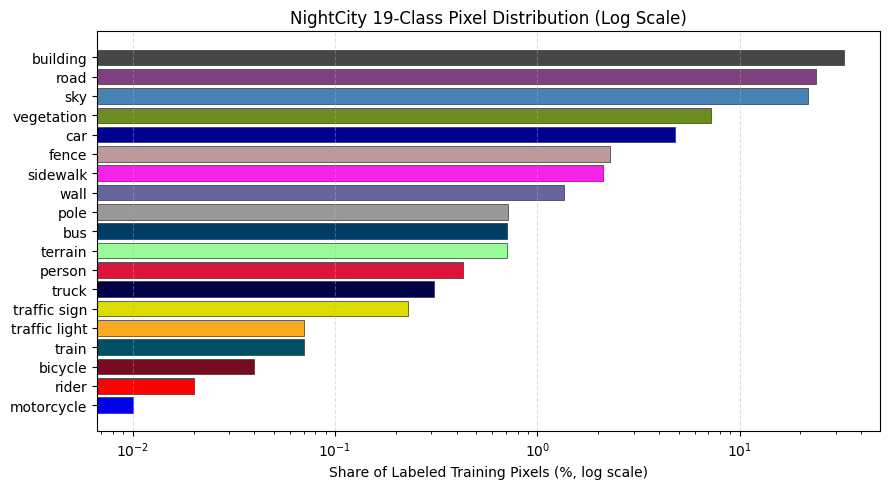

In [5]:
stats_file = DATA_ROOT / "nightcity_stats.json"
with open(stats_file, "r") as f:
    stats = json.load(f)

train_counts = np.array(stats["train_trainids"], dtype=np.int64)
val_counts = np.array(stats["val_trainids"], dtype=np.int64)
train_pct = train_counts[:19] / train_counts[:19].sum() * 100
val_pct = val_counts[:19] / val_counts[:19].sum() * 100

dist_df = pd.DataFrame({
    "ID": range(19),
    "Class": [c[0] for c in CLASSES],
    "Train %": np.round(train_pct, 2),
    "Val %": np.round(val_pct, 2),
}).sort_values("Train %", ascending=False)
display(dist_df.reset_index(drop=True))

void_pct = train_counts[19] / train_counts.sum() * 100
print(f"Void/Ignore pixels (train): {void_pct:.2f}% | Max/Min ratio: {train_pct.max() / train_pct.min():.1f}x")

fig, ax = plt.subplots(figsize=(9, 5))
plot_df = dist_df.sort_values("Train %", ascending=True)
colors = [np.array(CLASSES[i][1]) / 255.0 for i in plot_df["ID"]]
ax.barh(plot_df["Class"], plot_df["Train %"], color=colors, edgecolor="#333333", linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("Share of Labeled Training Pixels (%, log scale)")
ax.set_title("NightCity 19-Class Pixel Distribution (Log Scale)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

---
### 5. Multi-City Coverage & Low-Light Exposure

In [6]:
train_cities = Counter(p.stem.split("_")[0] for p in PATHS["train_images"].glob("*.png"))
val_cities = Counter(p.stem.split("_")[0] for p in PATHS["val_images"].glob("*.png"))
all_cities = sorted(set(train_cities) | set(val_cities), key=lambda c: -(train_cities[c] + val_cities[c]))

city_df = pd.DataFrame([
    {"City": c, "Train": train_cities[c], "Val": val_cities[c], "Total": train_cities[c] + val_cities[c]}
    for c in all_cities
])
display(city_df)

sample_imgs = sorted(PATHS["train_images"].glob("*.png"))[::30][:100]
means, dark_pcts, glare_pcts = [], [], []
for p in sample_imgs:
    arr = np.array(Image.open(p).convert("RGB"))
    gray = arr.mean(axis=2)
    means.append(gray.mean())
    dark_pcts.append((gray < 25).mean() * 100)
    glare_pcts.append((arr.max(axis=2) >= 245).mean() * 100)

print(f"Sampled {len(sample_imgs)} train images -> Mean intensity: {np.mean(means):.1f}/255 | "
      f"Dark pixels (<25): {np.mean(dark_pcts):.1f}% | Saturated glare (>=245): {np.mean(glare_pcts):.1f}%")

,City,Train,Val,Total
0,Nagoya,715,310,1025
1,Helsinki,460,199,659
2,Dubai,357,155,512
3,NYC,261,114,375
4,HK,256,111,367
5,Seoul,240,104,344
6,Chicago,136,59,195
7,Melbourne,128,55,183
8,tokyo,109,45,154
9,LA,103,45,148


Sampled 100 train images -> Mean intensity: 50.6/255 | Dark pixels (<25): 33.9% | Saturated glare (>=245): 1.5%


---
### 6. Sample Visuals & Preprocessing Verification

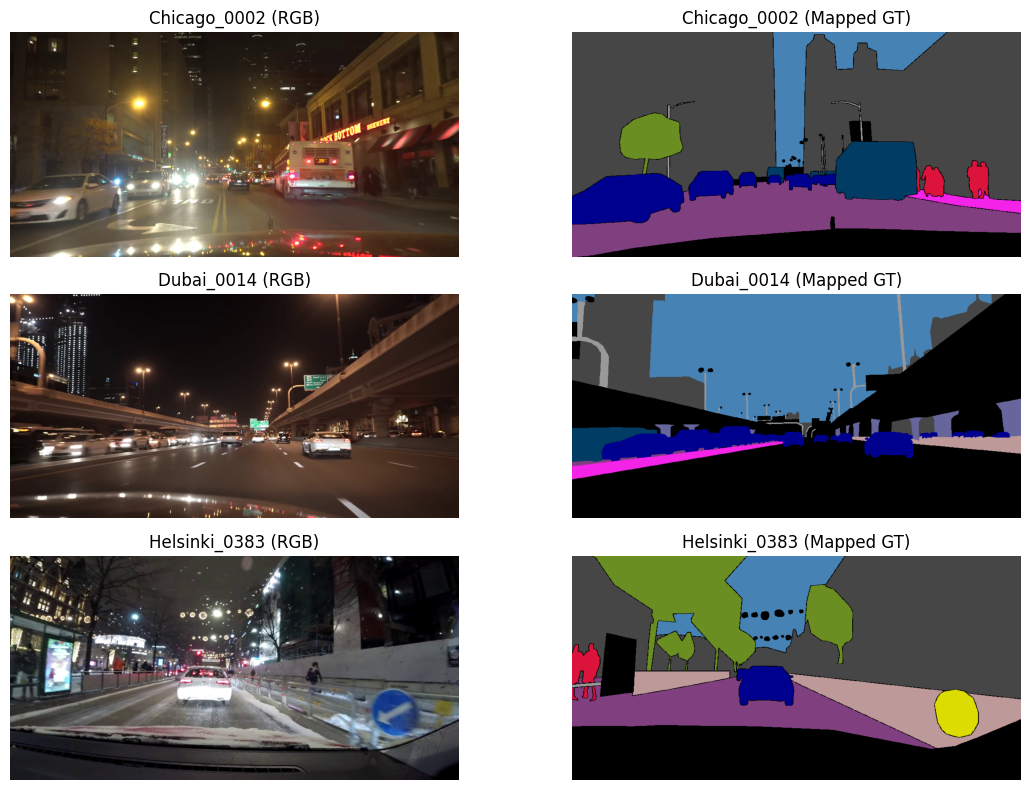

Image tensor: (3, 512, 1024) torch.float32 min=-2.04, max=2.64
Mask tensor:  (512, 1024) torch.int64 unique IDs: [0, 1, 2, 5, 8, 10, 11, 13, 15, 255]


In [7]:
sample_stems = ["Chicago_0002", "Dubai_0014", "Helsinki_0383"]
fig, axes = plt.subplots(len(sample_stems), 2, figsize=(12, 8))
for r, stem in enumerate(sample_stems):
    img = Image.open(PATHS["train_images"] / f"{stem}.png").convert("RGB")
    lbl = LABEL_LUT[np.array(Image.open(PATHS["train_labels"] / f"{stem}_labelIds.png"), dtype=np.uint8)]
    axes[r, 0].imshow(img)
    axes[r, 0].set_title(f"{stem} (RGB)")
    axes[r, 0].axis("off")
    axes[r, 1].imshow(PALETTE[lbl])
    axes[r, 1].set_title(f"{stem} (Mapped GT)")
    axes[r, 1].axis("off")
plt.tight_layout()
plt.show()

img_pil = Image.open(PATHS["train_images"] / f"{sample_stems[0]}.png").convert("RGB")
lbl_raw = np.array(Image.open(PATHS["train_labels"] / f"{sample_stems[0]}_labelIds.png"), dtype=np.uint8)
img_t = TF.normalize(TF.to_tensor(img_pil), mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
lbl_t = torch.from_numpy(LABEL_LUT[lbl_raw].astype(np.int64))

print("Image tensor:", tuple(img_t.shape), img_t.dtype, f"min={img_t.min():.2f}, max={img_t.max():.2f}")
print("Mask tensor: ", tuple(lbl_t.shape), lbl_t.dtype, "unique IDs:", torch.unique(lbl_t).tolist())